# 04 — Métricas de Classificação e o Limiar de Decisão

Nos notebooks 02 e 03, medimos os modelos com a **acurácia** e com uma "porcentagem da renda alta encontrada" improvisada. Vimos que a acurácia **engana** com classes desbalanceadas: o baseline acerta 76% sem encontrar ninguém.

Neste notebook vamos montar uma **caixa de ferramentas** de avaliação:
- **Precisão**, **recall** e **F1**: métricas focadas na classe que estamos procurando
- O **limiar de decisão**: por que 0,5 não é obrigatório e como escolher outro
- A **curva ROC** e a **AUC**: avaliar o modelo em **todos** os limiares de uma vez
- A **curva precisão-recall**, mais honesta quando a classe positiva é rara
- Escolher o limiar **sem enganar a si mesmo**, com o `TunedThresholdClassifierCV`

O modelo será sempre a regressão logística do notebook 03. O que muda é **como olhamos** para ela.

> Lembrete: execute as células em ordem com `Shift + Enter`.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Ferramentas novas deste notebook:
from sklearn.metrics import precision_score, recall_score, f1_score   # métricas da classe positiva
from sklearn.metrics import roc_curve, roc_auc_score                  # curva ROC e área sob ela
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import TunedThresholdClassifierCV         # escolhe o limiar com validação cruzada

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
colunas_categoricas = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]

# O modelo escolhido no notebook 03: logística com one-hot e categorias raras agrupadas.
preparar = ColumnTransformer([
    ("numericas", StandardScaler(), colunas_numericas),
    ("categoricas", Pipeline([
        ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
    ]), colunas_categoricas),
])
logistica = Pipeline([
    ("preparar", preparar),
    ("modelo", LogisticRegression(max_iter=1000)),
])

# A probabilidade "fora da dobra" de cada pessoa do treino (como no notebook 02).
# Vamos reaproveitar essas probabilidades em todo o notebook.
prob = cross_val_predict(logistica, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
previsao = (prob >= 0.5).astype(int)   # a regra padrão: limiar de 0,5

print(f"Acurácia com limiar 0,5: {accuracy_score(y_train, previsao):.2%}")

Acurácia com limiar 0,5: 85.15%


## 🎓 Conceito: precisão e recall

Voltemos à matriz de confusão:

| | Previsto `<=50K` | Previsto `>50K` |
|---|---|---|
| **Real `<=50K`** | VN | FP (alarme falso) |
| **Real `>50K`** | FN (passou despercebido) | VP |

Duas perguntas diferentes podem ser feitas sobre a classe positiva:

- **Precisão** (*precision*): **dos que o modelo apontou** como renda alta, quantos realmente são?
  $$\text{precisão} = \frac{VP}{VP + FP}$$
- **Recall** (ou **sensibilidade**): **dos que realmente são** renda alta, quantos o modelo encontrou?
  $$\text{recall} = \frac{VP}{VP + FN}$$

Analogia: um **pescador** joga a rede num lago.
- **Recall** é a fração dos peixes do lago que vieram na rede. Uma rede **enorme** pega todos os peixes (recall alto), mas também muito lixo.
- **Precisão** é a fração do que veio na rede que **é peixe**. Uma rede **pequena e cuidadosa** pega quase só peixe (precisão alta), mas deixa muitos para trás.

Repare que os denominadores são diferentes: a precisão olha para a **coluna** "Previsto `>50K`", e o recall olha para a **linha** "Real `>50K`". Nenhuma das duas usa os verdadeiros negativos, e é por isso que elas **não se deixam enganar** pela classe majoritária, como a acurácia se deixa.

No notebook 02, sem saber os nomes, já calculamos as duas: os "38,2% encontrados" eram o **recall**, e os "69,9% de previsões `>50K` corretas" eram a **precisão**.

## 2. Precisão e recall do nosso modelo

In [2]:
vn, fp, fn, vp = confusion_matrix(y_train, previsao).ravel()

# Calculando "à mão", direto das fórmulas:
precisao_mao = vp / (vp + fp)
recall_mao = vp / (vp + fn)

# E com as funções prontas do scikit-learn (devem dar o mesmo resultado):
print(f"VP={vp:,}  FP={fp:,}  FN={fn:,}  VN={vn:,}")
print(f"Precisão: {precisao_mao:.2%} (à mão)   {precision_score(y_train, previsao):.2%} (scikit-learn)")
print(f"Recall:   {recall_mao:.2%} (à mão)   {recall_score(y_train, previsao):.2%} (scikit-learn)")

VP=5,610  FP=2,064  FN=3,739  VN=27,660
Precisão: 73.10% (à mão)   73.10% (scikit-learn)
Recall:   60.01% (à mão)   60.01% (scikit-learn)


**Conclusão:** as contas "à mão" e as funções do scikit-learn dão o mesmo resultado:
- **Precisão de 73,10%:** de cada 100 pessoas que o modelo aponta como renda alta, ~73 realmente são.
- **Recall de 60,01%:** de cada 100 pessoas de renda alta, o modelo encontra ~60.

Comparando com o modelo só com as numéricas do notebook 02 (precisão 69,9%, recall 38,2%), as colunas categóricas melhoraram **as duas** métricas, e principalmente o recall.

## 🎓 Conceito: F1, uma nota única

Muitas vezes queremos **um único número** para comparar modelos. O **F1** combina precisão e recall usando a **média harmônica**:

$$F_1 = 2 \cdot \frac{\text{precisão} \cdot \text{recall}}{\text{precisão} + \text{recall}}$$

Por que não a média comum? Porque a média harmônica **pune desequilíbrios**. Um modelo com precisão 100% e recall 2% teria média comum de 51%, mas F1 de apenas **3,9%**. Para o F1 ser alto, **as duas** precisam ser altas.

Analogia: a nota de um decatleta não pode compensar um zero no salto em altura com um 10 na corrida. O F1 funciona como uma nota que exige bom desempenho nas duas provas.

Vamos ver os dois extremos "burros": sempre dizer `<=50K` e sempre dizer `>50K`.

In [3]:
def metricas(y_real, y_previsto):
    """Acurácia, precisão, recall e F1 num dicionário."""
    return {
        "acurácia": accuracy_score(y_real, y_previsto),
        # zero_division=0: se o modelo nunca prevê a classe 1, a precisão seria 0/0; definimos como 0.
        "precisão": precision_score(y_real, y_previsto, zero_division=0),
        "recall": recall_score(y_real, y_previsto),
        "F1": f1_score(y_real, y_previsto),
    }


# np.zeros_like / np.ones_like criam um array do mesmo tamanho, cheio de 0s ou de 1s.
tabela = pd.DataFrame({
    "Sempre <=50K (baseline)": metricas(y_train, np.zeros_like(y_train)),
    "Sempre >50K": metricas(y_train, np.ones_like(y_train)),
    "Logística (limiar 0,5)": metricas(y_train, previsao),
}).T
tabela

,acurácia,precisão,recall,F1
Sempre <=50K (baseline),0.7607,0.0000,0.0000,0.0000
Sempre >50K,0.2393,0.2393,1.0000,0.3861
"Logística (limiar 0,5)",0.8515,0.7310,0.6001,0.6591


**Conclusão:** a tabela mostra por que precisamos de mais de uma métrica:
- **Sempre `<=50K`:** acurácia de 76,07%, mas precisão, recall e F1 iguais a **zero**. As métricas da classe positiva denunciam na hora que esse "modelo" não encontra ninguém.
- **Sempre `>50K`:** recall **perfeito** (100%), porque aponta todo mundo. Mas a precisão é só 23,93% (a proporção de renda alta), e o F1 fica em 0,386. Um recall alto sozinho também não prova nada.
- **Logística:** F1 de **0,659**, bem acima dos dois extremos.

Cada métrica sozinha pode ser "enganada" por um modelo bobo. É olhando **várias ao mesmo tempo** (ou o F1, que combina duas) que vemos o quadro completo.

## 🎓 Conceito: o limiar de decisão

A regressão logística não devolve uma classe: devolve uma **probabilidade**. A classe vem de uma regra: "se a probabilidade for pelo menos o **limiar**, diga `>50K`". O scikit-learn usa **0,5** por padrão, mas isso é só uma convenção.

- **Baixar o limiar** (ex.: 0,3): o modelo aponta mais gente como renda alta. **Recall sobe** (encontra mais), **precisão cai** (mais alarmes falsos). É a rede grande do pescador.
- **Subir o limiar** (ex.: 0,7): o modelo só aponta quem tem probabilidade bem alta. **Precisão sobe**, **recall cai**. É a rede pequena.

Analogia: o **detector de metais** do aeroporto. Se ele for muito sensível (limiar baixo), apita para cintos e moedas: nenhuma arma passa, mas muita gente é revistada à toa. Se for pouco sensível (limiar alto), quase ninguém é revistado à toa, mas algo perigoso pode passar.

O ponto principal: **trocar o limiar não muda o modelo**, só a decisão tomada a partir das probabilidades. E não existe um limiar "certo" universal: ele depende do **custo** de cada tipo de erro.

## 3. O que acontece quando o limiar muda

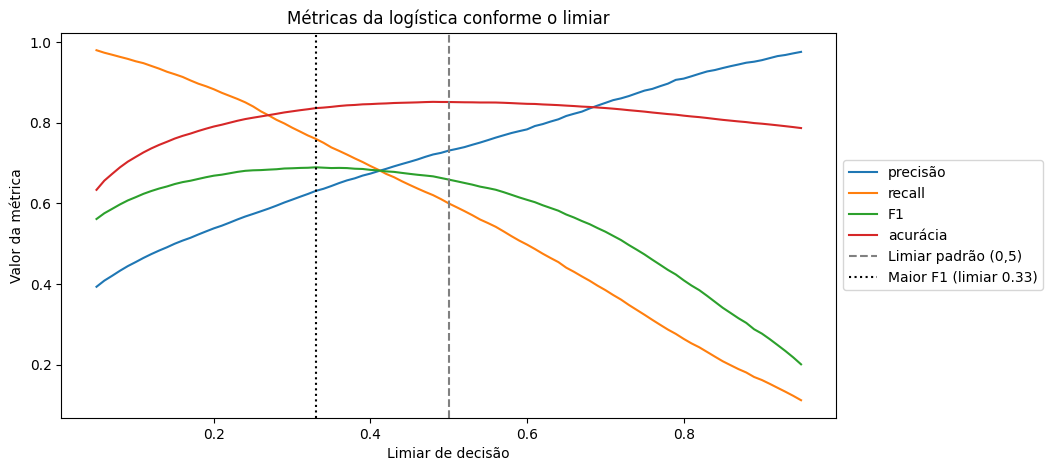

,acurácia,precisão,recall,F1
0.20,0.7908,0.5383,0.8830,0.6689
0.30,0.8284,0.6094,0.7878,0.6872
0.33,0.8363,0.6310,0.7602,0.6896
0.40,0.8463,0.6740,0.6927,0.6832
0.50,0.8515,0.7310,0.6001,0.6591
0.60,0.8470,0.7837,0.4979,0.6089
0.70,0.8365,0.8493,0.3852,0.5300


In [4]:
limiares = np.arange(0.05, 0.96, 0.01)   # de 0,05 a 0,95, de 0,01 em 0,01

# Para cada limiar, transformamos as probabilidades em classes e calculamos as métricas.
curvas = pd.DataFrame(
    [metricas(y_train, (prob >= limiar).astype(int)) for limiar in limiares],
    index=limiares.round(2),
)

melhor_limiar_f1 = curvas["F1"].idxmax()   # idxmax: o índice (aqui, o limiar) onde o F1 é máximo

fig, ax = plt.subplots(figsize=(10, 5))
for coluna in ["precisão", "recall", "F1", "acurácia"]:
    ax.plot(curvas.index, curvas[coluna], label=coluna)
ax.axvline(0.5, color="gray", linestyle="--", label="Limiar padrão (0,5)")
ax.axvline(melhor_limiar_f1, color="black", linestyle=":", label=f"Maior F1 (limiar {melhor_limiar_f1:.2f})")
ax.set_xlabel("Limiar de decisão")
ax.set_ylabel("Valor da métrica")
ax.set_title("Métricas da logística conforme o limiar")
# bbox_to_anchor coloca a legenda FORA do gráfico, à direita, para não cobrir as curvas.
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

curvas.loc[[0.2, 0.3, melhor_limiar_f1, 0.4, 0.5, 0.6, 0.7]]

**Conclusão:** o gráfico mostra a troca entre precisão e recall:
- Conforme o limiar **sobe**, a precisão (azul) sobe e o recall (laranja) cai. As curvas se cruzam perto de 0,41.
- A **acurácia** (vermelha) é quase plana entre 0,4 e 0,6 e atinge o máximo perto de 0,5 (85,15%). Ela praticamente não "sente" o limiar nessa região, mais um motivo para não usá-la como guia.
- O **F1 máximo** fica no limiar **0,33**: F1 de **0,690**, contra 0,659 no limiar 0,5. Com esse limiar, o recall sobe de 60,0% para **76,0%**, e a precisão cai de 73,1% para 63,1%. A acurácia cai um pouco (83,63%).

Repare: o limiar que maximiza o F1 **não** é o que maximiza a acurácia. Métricas diferentes levam a decisões diferentes, então escolher a métrica é parte do problema.

## 4. Escolhendo o limiar pelo custo dos erros

O F1 trata precisão e recall como igualmente importantes. Na vida real, quase nunca é assim. Imagine dois usos para este modelo:

1. **Campanha de divulgação** de um produto de investimento: enviar um folheto para quem o modelo aponta como renda alta. Um folheto custa pouco, e deixar de alcançar um cliente custa caro. Queremos **recall alto**, digamos de pelo menos **80%**.
2. **Pré-aprovação de um cartão premium**, sem análise humana: aprovar alguém sem renda para isso é caro. Queremos **precisão alta**, digamos de pelo menos **85%**.

In [5]:
# Para a campanha: o MAIOR limiar que ainda garante recall >= 80% (maior limiar = menos alarmes falsos).
limiar_campanha = curvas.index[curvas["recall"] >= 0.80].max()
# Para o cartão: o MENOR limiar que já garante precisão >= 85% (menor limiar = mais pessoas encontradas).
limiar_cartao = curvas.index[curvas["precisão"] >= 0.85].min()

cenarios = curvas.loc[[limiar_campanha, 0.5, limiar_cartao]].copy()
cenarios.index = [f"Campanha (limiar {limiar_campanha:.2f})", "Padrão (limiar 0.50)", f"Cartão (limiar {limiar_cartao:.2f})"]
# Quantas pessoas cada regra aponta como renda alta?
cenarios["apontados como >50K"] = [(prob >= l).sum() for l in [limiar_campanha, 0.5, limiar_cartao]]
cenarios

,acurácia,precisão,recall,F1,apontados como >50K
Campanha (limiar 0.28),0.8222,0.5946,0.8073,0.6848,12692
Padrão (limiar 0.50),0.8515,0.7310,0.6001,0.6591,7674
Cartão (limiar 0.71),0.8350,0.8561,0.3730,0.5196,4073


**Conclusão:** o **mesmo modelo** atende aos dois cenários, mudando só o limiar:
- **Campanha (limiar 0,28):** encontra **80,7%** das pessoas de renda alta. O preço é uma precisão de 59,5%: das 12.692 pessoas que recebem o folheto, ~40% não são o público-alvo. Para um folheto barato, é um bom negócio.
- **Cartão (limiar 0,71):** precisão de **85,6%**, ou seja, poucos aprovados sem renda. O preço é encontrar só 37,3% das pessoas de renda alta: só 4.073 pessoas são apontadas.
- O **limiar padrão (0,5)** fica no meio do caminho, com 7.674 pessoas apontadas.

Nenhum desses limiares é "o certo". O certo depende do **custo de cada erro**, e essa é uma decisão de **negócio**, não do algoritmo. O papel do cientista de dados é mostrar as opções com clareza, como nesta tabela.

## 🎓 Conceito: curva ROC e AUC

Até aqui, cada limiar gera uma matriz de confusão diferente. Como comparar **dois modelos** sem antes escolher um limiar? A **curva ROC** mostra o comportamento do modelo em **todos os limiares** de uma vez. Para cada limiar, ela marca um ponto com:
- **Eixo y — taxa de verdadeiros positivos** (é o recall): dos que são renda alta, quantos o modelo aponta.
- **Eixo x — taxa de falsos positivos**: dos que **não** são renda alta, quantos o modelo aponta por engano, ou seja, $FP / (FP + VN)$.

O limiar muito alto fica no canto (0, 0): ninguém é apontado. O limiar muito baixo fica no canto (1, 1): todo mundo é apontado. Um modelo perfeito passa pelo canto (0, 1): encontra todos sem nenhum alarme falso. Um modelo que **chuta** fica na diagonal.

A **AUC** (*area under the curve*, área sob a curva) resume a curva num número entre 0,5 (chute) e 1,0 (perfeito). Ela tem uma interpretação muito intuitiva:

> **AUC = a probabilidade de que, sorteando uma pessoa de renda alta e uma de renda baixa, o modelo dê uma probabilidade maior para a de renda alta.**

Ou seja, a AUC mede se o modelo sabe **ordenar** as pessoas, sem depender de limiar nenhum. Analogia: num concurso, a AUC não pergunta "quem passou?", e sim "os candidatos melhores ficaram na frente dos piores na lista de classificação?".

## 5. Curva ROC: comparando modelos

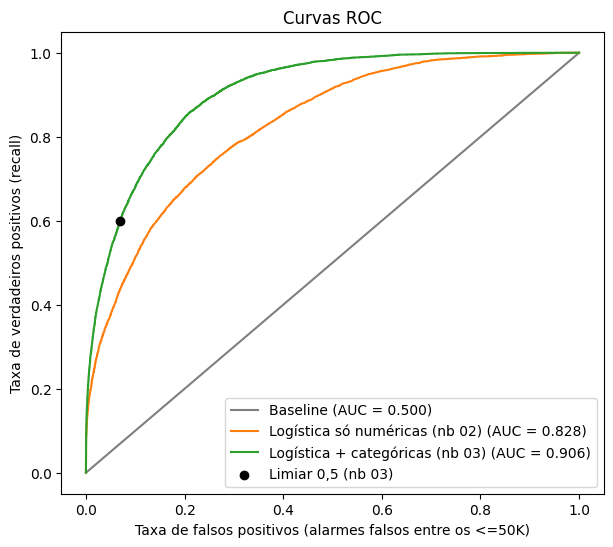

In [6]:
# Para comparar, as probabilidades de dois modelos mais fracos:
# o baseline (sempre a mesma probabilidade) e a logística só com as numéricas (notebook 02).
prob_baseline = cross_val_predict(DummyClassifier(), X_train[colunas_numericas], y_train,
                                  cv=cv, method="predict_proba")[:, 1]
logistica_numericas = Pipeline([("padronizar", StandardScaler()), ("modelo", LogisticRegression())])
prob_numericas = cross_val_predict(logistica_numericas, X_train[colunas_numericas], y_train,
                                   cv=cv, method="predict_proba")[:, 1]

probabilidades = {
    "Baseline": prob_baseline,
    "Logística só numéricas (nb 02)": prob_numericas,
    "Logística + categóricas (nb 03)": prob,
}
# Uma cor fixa para cada modelo, para que ele tenha a mesma cor nos dois gráficos (ROC e precisão-recall).
cores = {"Baseline": "tab:gray", "Logística só numéricas (nb 02)": "tab:orange", "Logística + categóricas (nb 03)": "tab:green"}

fig, ax = plt.subplots(figsize=(7, 6))
for nome, p in probabilidades.items():
    # roc_curve devolve as taxas de falsos e de verdadeiros positivos para cada limiar possível.
    taxa_fp, taxa_vp, _ = roc_curve(y_train, p)   # o "_" recebe os limiares, que não vamos usar
    auc = roc_auc_score(y_train, p)
    ax.plot(taxa_fp, taxa_vp, color=cores[nome], label=f"{nome} (AUC = {auc:.3f})")

# Marcando onde o limiar 0,5 do modelo completo cai na curva:
ax.scatter(fp / (fp + vn), vp / (vp + fn), color="black", zorder=3, label="Limiar 0,5 (nb 03)")
ax.set_xlabel("Taxa de falsos positivos (alarmes falsos entre os <=50K)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curvas ROC")
ax.legend(loc="lower right")
plt.show()

In [7]:
# Conferindo a interpretação da AUC "na força bruta": sorteamos 100 mil pares (renda alta, renda baixa)
# e contamos em quantos a pessoa de renda alta recebeu a probabilidade maior.
gerador = np.random.default_rng(42)   # gerador de números aleatórios com semente fixa
prob_altas = prob[y_train == 1]
prob_baixas = prob[y_train == 0]
# gerador.choice sorteia elementos de um array (com reposição).
pares_alta = gerador.choice(prob_altas, size=100_000)    # o _ em 100_000 só facilita a leitura do número
pares_baixa = gerador.choice(prob_baixas, size=100_000)
print(f"Pares em que a renda alta ficou na frente: {(pares_alta > pares_baixa).mean():.3f}")
print(f"AUC calculada pelo scikit-learn:            {roc_auc_score(y_train, prob):.3f}")

Pares em que a renda alta ficou na frente: 0.907
AUC calculada pelo scikit-learn:            0.906


**Conclusão:** - O **baseline** fica exatamente na diagonal (**AUC 0,500**): como dá a mesma probabilidade para todo mundo, ele não sabe ordenar ninguém.
- A logística **só com as numéricas** tem **AUC 0,828**, e a logística **com as categóricas** tem **AUC 0,906**. A curva verde fica acima da laranja em **todos** os limiares: o modelo do notebook 03 é melhor qualquer que seja o limiar escolhido.
- O ponto preto mostra onde o limiar 0,5 cai na curva verde: recall de 60% com 6,9% de alarmes falsos entre os `<=50K`. Mover o limiar é **andar sobre a curva**.
- A interpretação da AUC confere: em **90,7%** dos 100 mil pares sorteados, a pessoa de renda alta recebeu a probabilidade maior, praticamente igual à AUC de **0,906**. A pequena diferença vem do sorteio.

## 🎓 Conceito: curva precisão-recall

A curva ROC tem um ponto cego com classes desbalanceadas. O eixo x divide os falsos positivos pelos **~30 mil** negativos. Então 1.000 alarmes falsos viram só 3% no eixo x e parecem pouco, mesmo que, para quem recebe a lista de "renda alta", eles sejam muitos.

A **curva precisão-recall** coloca o **recall** no eixo x e a **precisão** no eixo y, também para todos os limiares. Ela olha **só** para a classe positiva, e por isso mostra melhor o "custo" dos alarmes falsos.

O resumo dela é a **precisão média** (*average precision*, AP). A referência de "chute" aqui **não é 0,5**: é a **proporção de positivos** (23,9%), porque um modelo que chuta tem precisão igual a essa proporção em qualquer recall.

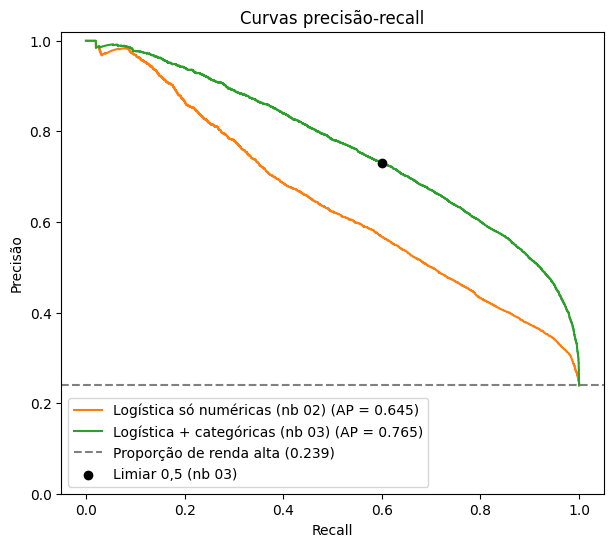

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
for nome, p in probabilidades.items():
    if nome == "Baseline":
        continue   # continue pula para a próxima volta do laço: o baseline aqui é a linha tracejada
    precisoes, recalls, _ = precision_recall_curve(y_train, p)
    ap = average_precision_score(y_train, p)
    ax.plot(recalls, precisoes, color=cores[nome], label=f"{nome} (AP = {ap:.3f})")

ax.axhline(y_train.mean(), color="gray", linestyle="--", label=f"Proporção de renda alta ({y_train.mean():.3f})")
ax.scatter(vp / (vp + fn), vp / (vp + fp), color="black", zorder=3, label="Limiar 0,5 (nb 03)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisão")
ax.set_ylim(0, 1.02)
ax.set_title("Curvas precisão-recall")
ax.legend(loc="lower left")
plt.show()

**Conclusão:** - A referência de "chute" é a linha tracejada em **0,239**, e não 0,5 como na ROC.
- A logística só com as numéricas tem **AP 0,645**, e a com as categóricas tem **AP 0,765**. De novo, a curva do modelo do notebook 03 fica acima da outra em praticamente todos os recalls.
- O gráfico mostra o custo de encontrar mais gente: para passar de 60% para 90% de recall, a precisão do modelo completo cai de ~73% para ~52%.

**Qual curva usar?** As duas contam a mesma história aqui: o modelo com categóricas é melhor. A **ROC/AUC** é a mais usada e fácil de interpretar ("probabilidade de ordenar certo um par"). A **precisão-recall** é mais informativa quando a classe positiva é **rara** e quando os alarmes falsos importam. Neste problema (24% de positivos), as duas são úteis.

## 6. Escolher o limiar sem enganar a si mesmo

Na seção 3, encontramos o limiar de maior F1 olhando para as **mesmas** previsões em que depois medimos o F1. Isso é parecido com a "maldição do vencedor" do ML-01 (notebook 06): escolher e avaliar com os mesmos dados dá um resultado **otimista**.

O jeito correto é tratar o limiar como um **hiperparâmetro**: escolhê-lo com validação cruzada **dentro do treino** de cada dobra, e avaliar na dobra de validação, que não participou da escolha. O scikit-learn tem uma ferramenta pronta para isso, o **`TunedThresholdClassifierCV`**:
- Ele recebe um modelo e uma métrica (aqui, o F1).
- No `fit`, faz uma validação cruzada **interna** para descobrir o limiar que maximiza a métrica, e depois treina o modelo com todos os dados recebidos.
- No `predict`, usa esse limiar em vez de 0,5.

Colocando-o dentro de um `cross_validate`, temos uma **validação cruzada dentro de outra** (*nested cross-validation*). Isso treina 5 × 5 = 25 modelos, mais os retreinos, e leva alguns segundos.

In [9]:
logistica_limiar_ajustado = TunedThresholdClassifierCV(
    logistica,        # o pipeline completo do notebook 03
    scoring="f1",     # a métrica que o limiar deve maximizar
    cv=cv,            # validação cruzada interna, para escolher o limiar
)

metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]
resultados = {}
for nome, modelo in [("Logística (limiar 0,5)", logistica), ("Logística (limiar ajustado p/ F1)", logistica_limiar_ajustado)]:
    # return_estimator=True devolve os 5 modelos treinados, um por dobra.
    cv_resultado = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas_cv, return_estimator=True)
    # Um "dict comprehension": como a list comprehension, mas criando um dicionário {chave: valor}.
    resultados[nome] = {m: cv_resultado[f"test_{m}"].mean() for m in metricas_cv}
    resultados[nome]["± desvio F1"] = cv_resultado["test_f1"].std()
    if nome.endswith("F1)"):
        # best_threshold_ é o limiar escolhido pela validação cruzada interna em cada dobra.
        # float(...) converte o número do NumPy num float comum do Python, que é exibido de forma mais limpa.
        limiares_escolhidos = [round(float(est.best_threshold_), 3) for est in cv_resultado["estimator"]]

print("Limiar escolhido em cada dobra:", limiares_escolhidos)
# rename troca os nomes das colunas usando um dicionário {nome antigo: nome novo}.
pd.DataFrame(resultados).T.rename(columns={
    "accuracy": "acurácia", "precision": "precisão", "f1": "F1", "roc_auc": "AUC",
})

Limiar escolhido em cada dobra: [0.333, 0.333, 0.333, 0.323, 0.333]


,acurácia,precisão,recall,F1,AUC,± desvio F1
"Logística (limiar 0,5)",0.8515,0.7312,0.6001,0.6591,0.9064,0.0092
Logística (limiar ajustado p/ F1),0.8360,0.6316,0.7564,0.6882,0.9064,0.0104


**Conclusão:** - O limiar escolhido **dentro** de cada dobra ficou entre **0,323 e 0,333**, muito estável e igual ao 0,33 da seção 3.
- O F1 avaliado de forma honesta ficou em **0,688**, contra o **0,690** "otimista" da seção 3. A diferença é pequena porque escolhemos só **um** número (o limiar) com quase 40 mil pessoas, mas o procedimento correto é este, e com menos dados a diferença pode ser grande.
- Com o limiar ajustado, o **recall** sobe de 60,0% para **75,6%** e a **precisão** cai de 73,1% para 63,2%. A **acurácia** cai de 85,15% para 83,60%: otimizar o F1 **piora** a acurácia, mais uma prova de que as métricas medem coisas diferentes.
- A **AUC é idêntica** (0,9064) nos dois casos. Isso faz sentido: mudar o limiar não muda as probabilidades, então não muda a **ordem** das pessoas, que é o que a AUC mede.

## 7. Resumo e próximos passos

**Resultados (validação cruzada no treino, logística do notebook 03)**

| Limiar | Acurácia | Precisão | Recall | F1 | AUC |
|---|---|---|---|---|---|
| 0,5 (padrão) | **85,15%** | **73,1%** | 60,0% | 0,659 | 0,906 |
| Ajustado para o F1 (~0,33) | 83,60% | 63,2% | **75,6%** | **0,688** | 0,906 |

**Conceitos que você aprendeu**
- **Precisão** (dos apontados, quantos acertei?) e **recall** (dos que existem, quantos encontrei?).
- **F1**: média harmônica, que exige precisão **e** recall altos.
- O **limiar de decisão** e a troca entre precisão e recall; escolher o limiar pelo **custo dos erros**.
- **Curva ROC** e **AUC**: a probabilidade de ordenar certo um par (renda alta, renda baixa), independente do limiar.
- **Curva precisão-recall** e **precisão média (AP)**, cuja referência é a proporção de positivos.
- Escolher o limiar como um **hiperparâmetro**, com **validação cruzada aninhada** (`TunedThresholdClassifierCV`).

**Python novo:** `precision_score`, `recall_score`, `f1_score` (`zero_division`), `np.zeros_like`/`np.ones_like`, `idxmax`, `roc_curve`, `roc_auc_score`, `precision_recall_curve`, `average_precision_score`, `np.random.default_rng` e `.choice`, `100_000`, `continue`, dict comprehension, `return_estimator=True`, `.rename(columns=...)` e a legenda fora do gráfico com `bbox_to_anchor`.

**Como vamos avaliar daqui em diante**
- Para **comparar modelos**: a **AUC**, que não depende do limiar. Um modelo com AUC maior ordena melhor as pessoas, e qualquer limiar pode ser ajustado depois.
- Para a **decisão final**: o F1 com o limiar ajustado, sabendo que outro critério de custo levaria a outro limiar.

**Próximo notebook (05):** modelos de árvore para classificação. A regressão logística é um modelo **linear**: ela não consegue representar a curva em "U" invertido da idade (notebook 01) nem o "degrau" do ganho de capital (notebook 03). Vamos testar a **árvore de decisão**, a **random forest** e o **gradient boosting**, como no ML-01, agora classificando, e comparar todos pela AUC.